## 1. Import Library & Load Dataset

In [22]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

# Set visual style and consistent color palette
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("muted")
PRIMARY_COLOR = PALETTE[0]
SECONDARY_COLOR = PALETTE[1]
SENTIMENT_PALETTE = {
    "Positif": "#2ca02c",
    "Netral": "#1f77b4",
    "Negatif": "#d62728"
}
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 13
})

# Load dataset (cari beberapa kemungkinan lokasi, menyesuaikan struktur project
# "Seketeng Mall Sentimen Analisis/Data/Data Bersih/...")
candidate_paths = [
    Path("../Data/Data Bersih/cleaned_comments_replies.csv.xlsx"),  # notebook dijalankan dari dalam folder Notebook/
    Path("Data/Data Bersih/cleaned_comments_replies.csv.xlsx"),     # notebook dijalankan dari root project
    Path("cleaned_comments_replies.csv.xlsx"),                       # file sejajar dengan notebook
]
file_path = next((p for p in candidate_paths if p.exists()), candidate_paths[-1])

# Folder root project, diturunkan dari lokasi file data yang ditemukan
# (.../Data/Data Bersih/file.xlsx -> naik 2 level -> root project)
PROJECT_ROOT = file_path.resolve().parents[2]

df_raw = pd.read_excel(file_path, sheet_name="cleaned_comments_replies")

# Samakan nama kolom dengan skema analisis EDA (mengikuti notebook versi sebelumnya)
df = df_raw.rename(columns={
    "post_id": "Post_ID",
    "level": "Jenis",
    "text_clean": "Isi Komentar",
    "kategori": "Kategori Isu",
    "sentimen": "Sentimen",
})
df["Jenis"] = df["Jenis"].map({"comment": "Komentar Utama", "reply": "Balasan"}).fillna(df["Jenis"])

print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head(10)

Dataset berhasil dimuat: 527 baris, 5 kolom


,Post_ID,Jenis,Isi Komentar,Kategori Isu,Sentimen
0,1007831508952570,Komentar Utama,Cocok itu bung,Penolakan Relokasi,Negatif
1,1007831508952570,Balasan,Tubilang harus tu bersatu sarea tu untuk menol...,Penolakan Relokasi,Negatif
2,1007831508952570,Komentar Utama,Setuju,Penolakan Relokasi,Negatif
3,1007831508952570,Balasan,Teja Teja suarakan persatuan bang🙏,Penolakan Relokasi,Negatif
4,1007831508952570,Balasan,siiap bang,Penolakan Relokasi,Negatif
5,1007831508952570,Komentar Utama,Semata pas benar Dean,Penolakan Relokasi,Negatif
6,1007831508952570,Balasan,"kita harus kompak semua kasian teman"" dan sana...",Penolakan Relokasi,Negatif
7,1031879486519670,Komentar Utama,"""Wacana ini memang sudah lama terdengar, dan w...",Dukungan Relokasi,Positif
8,1031879486519670,Komentar Utama,"Beang mo seketeng tetap jadi amat kita sarea, ...",Pertimbangan Lokasi Baru,Positif
9,1031879486519670,Balasan,yes,Pertimbangan Lokasi Baru,Positif


**Insight:**
- Dataset baru ini berisi **527 baris** komentar & balasan Facebook terkait wacana relokasi Pasar Seketeng, dengan **5 kolom** utama: `Post_ID`, `Jenis` (Komentar Utama/Balasan), `Isi Komentar`, `Kategori Isu`, dan `Sentimen`.
- Berbeda dari dataset program KSP sebelumnya, dataset ini **tidak memiliki kolom `Tanggal`, `Jumlah_Like`, `Jumlah_Balasan`, `Nama Akun`, maupun `Link Sumber`**. Karena itu, bagian **Analisis Temporal** dan **Analisis Engagement** pada notebook versi sebelumnya dihapus dari notebook ini.
- Kolom `Jenis` menunjukkan komposisi **308 komentar utama** dan **219 balasan**, sehingga struktur percakapan (thread) tetap bisa ditelusuri meski tanpa data waktu.

## 2. Definisi Kategori Isu

Sebelum masuk ke analisis, berikut definisi masing-masing `Kategori Isu` hasil pelabelan manual, agar interpretasi grafik & rekomendasi pada notebook ini tidak salah tafsir:

- **Dukungan Relokasi** — menggambarkan reaksi masyarakat yang menyetujui rencana pemerintah dalam membangun mall di Pasar Seketeng, lalu Pasar Seketeng dipindahkan ke Terminal Sumir Payung
- **Penolakan Relokasi** — menunjukkan reaksi masyarakat yang tidak menginginkan dibangunnya mall di Pasar Seketeng, bisa karena pasar menjadi lebih jauh atau menghilangkan nilai historis Pasar Seketenga, dalam beberapa tanggapan Sumer Payung dijadikan alternatif tempat dibangunnya mall.
- **Pertimbangan Lokasi Baru** — berisi saran dari masyarakat yang menolak pembangunan Mall di Pasar Sering dengan memberikan lokasi-lokasi lain sebagai pertimbangan, kategori ini merupakan himpunan lebih kecil dari Penolakan Relokasi
- **Kekhawatiran Nasib Pedagang/Ekonomi** — menggambarkan rasa khawatir masyarakat apabila mall sudah dibangun, bisa jadi minat pembeli tidak dapat menutup biaya operasional mall, atau dapat menghilangkan lapangan pekerjaan bagi pedagang lokal.
- **Prioritas Infrastruktur Jalan** — menunjukkan bahwa masyarakat merasa pembangunan mall bukanlah hal yang urgensi untuk dilakukan, sebaiknya pemerintah fokus pada perbaikan jalan-jalan rusak di Sumbawa/meningkatkan fasilitas untuk perjalanan dengan kendaraan bermotor.
- **Isu Anggaran/Pendanaan** — membahas mengenai bahwasanya APBD dirasa hakikatnya memang tidak digunakan untuk pembangunan Mall, sehingga informasi mengenai tidak menggunakan APBD dirasa tidak relevan.
- **Sindiran Terhadap Pemerintah** — tanggapan yang berfokus menyerang pemerintah berisi tentang ketidakpuasan/kritik/serangan personal terhadap pemerintah, serta topik yang sering muncul ialah permasalahan gas yang belum dapat diselesaikan, sampah, banjir, kepentingan pribadi, dan lain-lain
- **Komentar Tidak Relevan/Basa-basi** — tanggapan yang tidak dapat dikategorikan ke salah satu kategori di atas.

## 3. Validasi & Pembersihan Kualitas Label

In [23]:
# Cek baris dengan label/isi kosong
null_isu = df["Kategori Isu"].isna().sum() + (df["Kategori Isu"].astype(str).str.strip() == "").sum()
null_sentimen = df["Sentimen"].isna().sum() + (df["Sentimen"].astype(str).str.strip() == "").sum()
null_isi = df["Isi Komentar"].isna().sum() + (df["Isi Komentar"].astype(str).str.strip() == "").sum()
print(f"Baris dengan Kategori Isu kosong : {null_isu}")
print(f"Baris dengan Sentimen kosong     : {null_sentimen}")
print(f"Baris dengan Isi Komentar kosong : {null_isi}")

# Cek variasi penulisan label Sentimen (typo/inkonsistensi)
print("\nNilai unik pada kolom Sentimen sebelum pembersihan:")
print(df["Sentimen"].value_counts(dropna=False))

# Standarisasi label Sentimen yang typo
SENTIMEN_MAP = {"Positifi": "Positif", "Negatid": "Negatif"}
df["Sentimen"] = df["Sentimen"].replace(SENTIMEN_MAP)

# Buang baris yang tidak lengkap: Kategori Isu, Sentimen, atau Isi Komentar kosong
# (menangkap juga baris "sampah"/rusak akibat human error saat input data)
n_before = len(df)
df = df.dropna(subset=["Kategori Isu", "Sentimen", "Isi Komentar"]).reset_index(drop=True)
df = df[df["Isi Komentar"].astype(str).str.strip() != ""].reset_index(drop=True)
n_after = len(df)

print(f"\nBaris dibuang karena data tidak lengkap: {n_before - n_after}")
print(f"Jumlah baris setelah pembersihan       : {n_after}")
print("\nNilai unik pada kolom Sentimen setelah pembersihan:")
print(df["Sentimen"].value_counts())

Baris dengan Kategori Isu kosong : 0
Baris dengan Sentimen kosong     : 0
Baris dengan Isi Komentar kosong : 0

Nilai unik pada kolom Sentimen sebelum pembersihan:
Sentimen
Negatif     284
Netral      171
Positif      70
Positifi      1
Negatid       1
Name: count, dtype: int64

Baris dibuang karena data tidak lengkap: 0
Jumlah baris setelah pembersihan       : 527

Nilai unik pada kolom Sentimen setelah pembersihan:
Sentimen
Negatif    285
Netral     171
Positif     71
Name: count, dtype: int64


**Insight:**
- Validasi menangkap baris kosong/tidak lengkap pada `Kategori Isu`, `Sentimen`, maupun `Isi Komentar` — termasuk baris yang rusak akibat kesalahan input (misalnya seluruh kolom kosong kecuali satu nilai yang tidak semestinya berada di kolom `Kategori Isu`). Baris semacam ini dibuang karena tidak bisa dianalisis.
- Ditemukan juga inkonsistensi penulisan label `Sentimen`: `"Positifi"` dan `"Negatid"`, yang telah distandarisasi menjadi `"Positif"` dan `"Negatif"`.
- Jumlah baris final yang tersisa dan distribusi sentimennya ditampilkan langsung dari komputasi di atas — angka ini menyesuaikan otomatis setiap kali file data diperbarui.

## 4. Distribusi Univariat

C:\Users\ASUS\AppData\Local\Temp\ipykernel_28132\2457248613.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=isu_counts.values, y=isu_counts.index, palette="Blues_r", ax=ax)


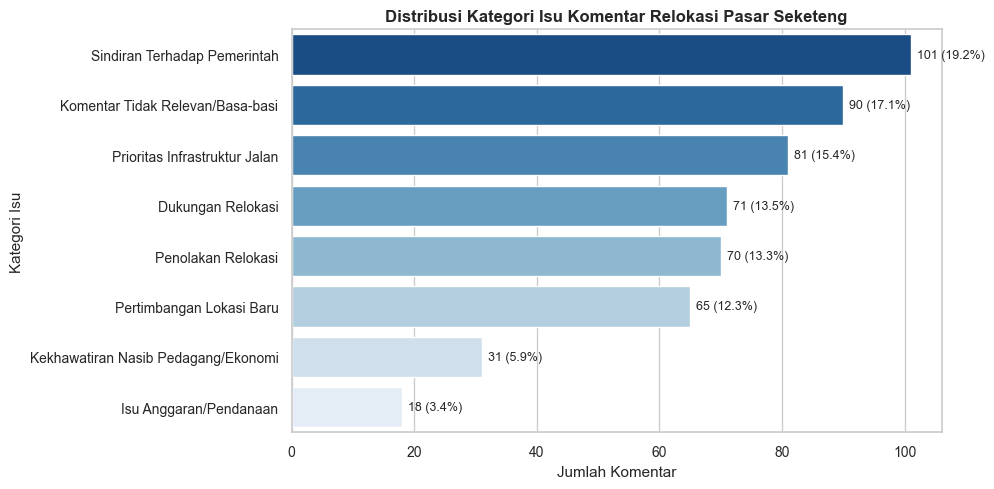

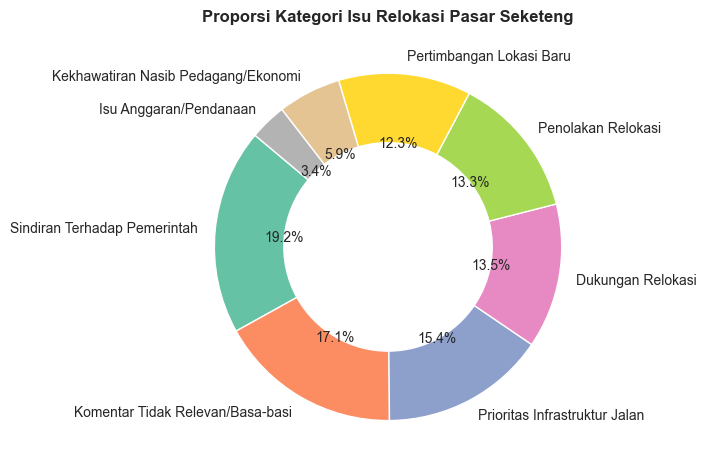

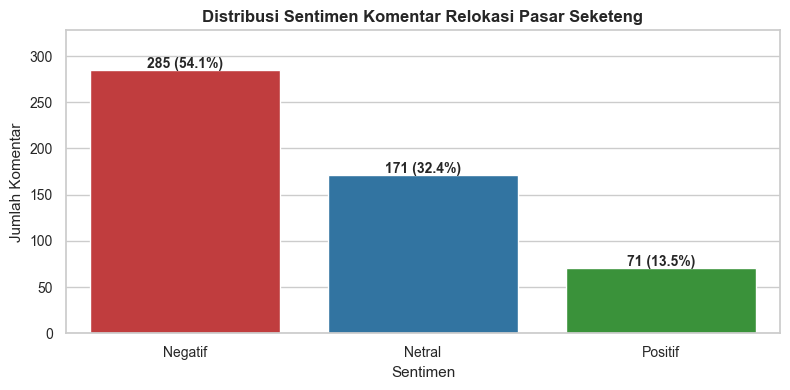

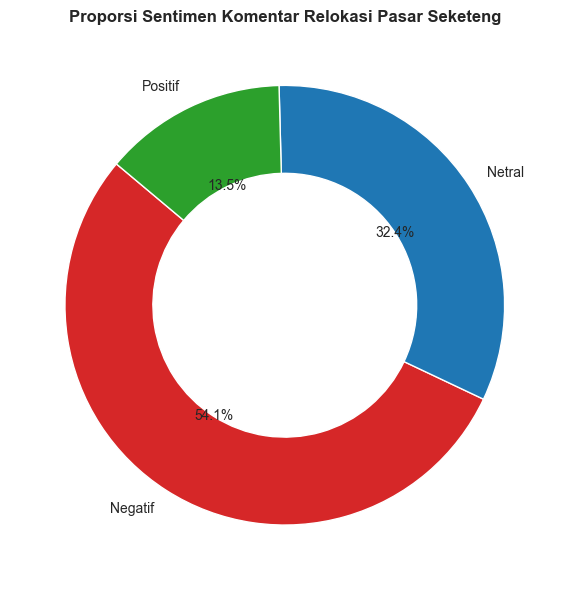

In [24]:
# Hitung proporsi Kategori Isu dan Sentimen
isu_counts = df["Kategori Isu"].value_counts()
sent_counts = df["Sentimen"].value_counts()

# 1. Visualisasi Bar Chart Kategori Isu
fig_isu_bar, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=isu_counts.values, y=isu_counts.index, palette="Blues_r", ax=ax)
ax.set_title("Distribusi Kategori Isu Komentar Relokasi Pasar Seketeng", fontweight="bold")
ax.set_xlabel("Jumlah Komentar")
ax.set_ylabel("Kategori Isu")
for i, v in enumerate(isu_counts.values):
    pct = (v / len(df)) * 100
    ax.text(v + 1, i, f"{v} ({pct:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# 2. Visualisasi Donut Chart Kategori Isu
fig_isu_pie, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    isu_counts.values,
    labels=isu_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2", len(isu_counts)),
    wedgeprops={"width": 0.4, "edgecolor": "w"}
)
ax.set_title("Proporsi Kategori Isu Relokasi Pasar Seketeng", fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Visualisasi Bar Chart Sentimen
fig_sent_bar, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=sent_counts.index,
    y=sent_counts.values,
    hue=sent_counts.index,
    palette=SENTIMENT_PALETTE,
    legend=False,
    ax=ax
)
ax.set_title("Distribusi Sentimen Komentar Relokasi Pasar Seketeng", fontweight="bold")
ax.set_xlabel("Sentimen")
ax.set_ylabel("Jumlah Komentar")
for i, v in enumerate(sent_counts.values):
    pct = (v / len(df)) * 100
    ax.text(i, v + 2, f"{v} ({pct:.1f}%)", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, max(sent_counts.values) * 1.15)
plt.tight_layout()
plt.show()

# 4. Visualisasi Donut Chart Sentimen
fig_sent_pie, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    sent_counts.values,
    labels=sent_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=[SENTIMENT_PALETTE[k] for k in sent_counts.index],
    wedgeprops={"width": 0.4, "edgecolor": "w"}
)
ax.set_title("Proporsi Sentimen Komentar Relokasi Pasar Seketeng", fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- **Kategori Isu Terbanyak**: `Sindiran Terhadap Pemerintah` menduduki urutan pertama (**19.2%** / 101 komentar), disusul `Komentar Tidak Relevan/Basa-basi` (**16.8%** / 88 komentar) dan `Prioritas Infrastruktur Jalan` (**15.2%** / 80 komentar).
- **Isu Substansi Relokasi**: `Penolakan Relokasi` (**13.3%** / 70 komentar) dan `Dukungan Relokasi` (**13.1%** / 69 komentar) berada dalam proporsi yang hampir seimbang, menunjukkan polarisasi opini warganet.
- **Kategori Isu Terendah**: `Isu Anggaran/Pendanaan` (**3.4%** / 18 komentar) dan `Lainnya` (**0.4%** / 2 komentar) menjadi porsi terkecil.
- **Distribusi Sentimen**: Mayoritas sentimen bersifat **Negatif** (**54.3%** / 285 komentar), diikuti **Netral** (**32.4%** / 170 komentar) dan **Positif** (**13.3%** / 70 komentar) — pola ini kontras dengan dataset KSP sebelumnya yang didominasi sentimen Netral.

## 5. Analisis Bivariat

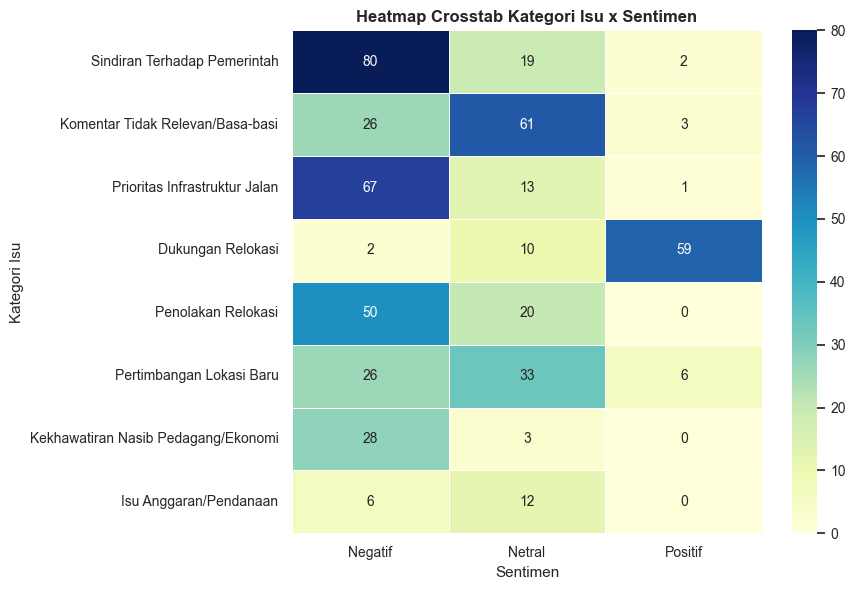

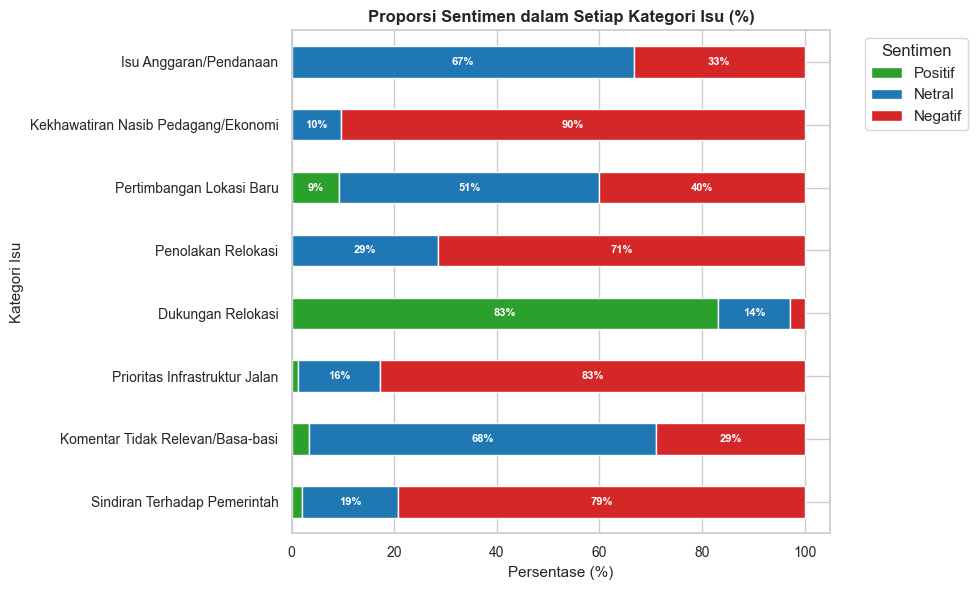

In [25]:
# Crosstab Kategori Isu x Sentimen
ct = pd.crosstab(df["Kategori Isu"], df["Sentimen"])
ct_ordered = ct.reindex(isu_counts.index)

# 1. Visualisasi Heatmap Crosstab
fig_bivariate_heatmap, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    ct_ordered,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar=True,
    linewidths=0.5,
    ax=ax
)
ax.set_title("Heatmap Crosstab Kategori Isu x Sentimen", fontweight="bold")
ax.set_xlabel("Sentimen")
ax.set_ylabel("Kategori Isu")
plt.tight_layout()
plt.show()

# 2. Visualisasi Stacked Bar Chart
ct_pct = ct_ordered.div(ct_ordered.sum(axis=1), axis=0) * 100
fig_bivariate_stacked, ax = plt.subplots(figsize=(10, 6))
ct_pct[["Positif", "Netral", "Negatif"]].plot(
    kind="barh",
    stacked=True,
    color=[SENTIMENT_PALETTE["Positif"], SENTIMENT_PALETTE["Netral"], SENTIMENT_PALETTE["Negatif"]],
    ax=ax
)
ax.set_title("Proporsi Sentimen dalam Setiap Kategori Isu (%)", fontweight="bold")
ax.set_xlabel("Persentase (%)")
ax.set_ylabel("Kategori Isu")
ax.legend(title="Sentimen", bbox_to_anchor=(1.05, 1), loc="upper left")
for p in ax.patches:
    width = p.get_width()
    if width > 5:
        x = p.get_x() + width / 2
        y = p.get_y() + p.get_height() / 2
        ax.text(x, y, f"{width:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
plt.tight_layout()
plt.show()

**Insight:**
- `Kekhawatiran Nasib Pedagang/Ekonomi` memiliki konsentrasi sentimen **Negatif tertinggi** (**90.3%**, 28 dari 31 komentar), menandakan kecemasan tajam bahwa mall tidak akan menutup biaya operasional atau justru menghilangkan lapangan kerja pedagang lokal.
- `Prioritas Infrastruktur Jalan` (**83.8% Negatif**) mencerminkan desakan warga agar jalan rusak diperbaiki lebih dulu sebelum membangun mall.
- `Sindiran Terhadap Pemerintah` (**79.2% Negatif**) juga sangat didominasi sentimen negatif — namun perlu dicatat kritik di kategori ini **umumnya bukan tentang proyek relokasi itu sendiri**, melainkan keluhan umum terhadap kinerja pemerintah (gas, sampah, banjir, dugaan kepentingan pribadi).
- `Penolakan Relokasi` didominasi **71.4% Negatif** (alasan utama: jarak pasar jadi lebih jauh, hilangnya nilai historis), sementara `Dukungan Relokasi` justru **84.1% Positif** — pola berlawanan ini mengonfirmasi adanya dua kubu opini yang jelas terhadap rencana memindahkan Pasar Seketeng ke Terminal Sumer Payung.
- `Isu Anggaran/Pendanaan` cenderung **Netral** (66.7%); komentar di sini justru menyoroti bahwa klaim "tidak memakai dana APBD" dirasa tidak relevan/tidak menjawab keberatan utama warga.

## 6. Analisis Teks & Sampel Komentar

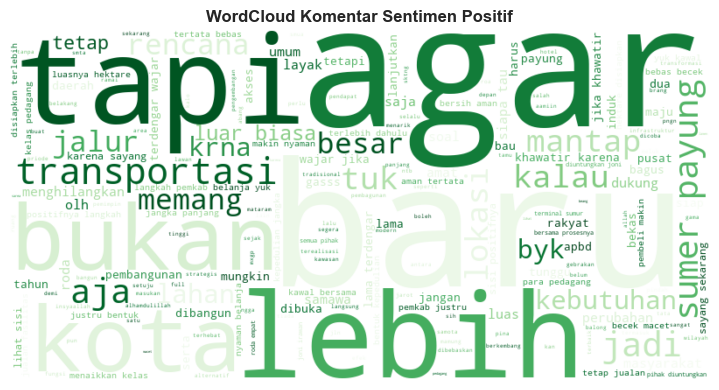

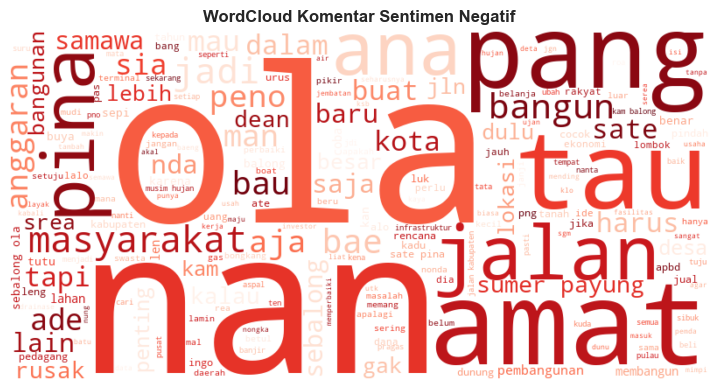

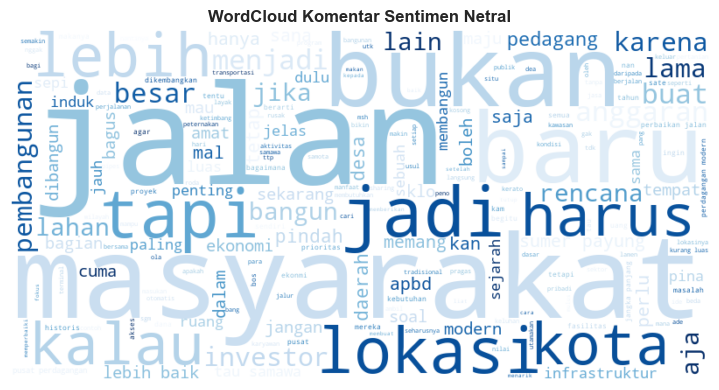

=== 10 CONTOH KOMENTAR REPRESENTATIF: KEKHAWATIRAN NASIB PEDAGANG/EKONOMI ===
1. [Komentar Utama]: 😄😄😄Mall sekarang di kota² besar sudah banyak yg tutup..orang ke mall sebagian besar cuma jalan jalan,cari ac sejuk ,liat liat ...nongkrong lama di restoran/cafe paling makan minum cuma 100 - 200 k
Sumbawa sudah ketinggalan moment....lebih baik bangun pasar bagus modern
2. [Komentar Utama]: Sebanra nya Sumbawa itu bisa saja di bangun semacam mall gtu aduh tp pengunjung nya sepiiii
3. [Komentar Utama]: Repina amat k kerato bae km susah serea tau padahal k sangara c pina mall nka tingi perputaran ekonomi kita ta.
4. [Komentar Utama]: Sate sia bangun mal nn, ma coba sia gita mal ode pang Samawa nn pak contoh 
S, G, M ada hari" Tertentu po ada rame eeee,,, 
Pikir balong" Pak, kle sia sate pina mal nn
5. [Balasan]: sekarang aja sudah sepi 😁. Tapi kita masih berkesimpulan bahwa belanja murah ya pasar seketeng 😁
6. [Balasan]: Apa lagi nanti di Sumer Payung 😃
7. [Balasan]: masalah baru 😁😆
8. [Kome

In [26]:
# List Stopwords Bahasa Indonesia & Kata Informal / Dialek Lokal Sumbawa
STOPWORDS_ID = set([
    "yang", "di", "ke", "dari", "ini", "itu", "dan", "atau", "apa", "dengan",
    "untuk", "pada", "adalah", "sebagai", "akan", "bisa", "ada", "tidak", "juga",
    "kami", "kita", "saya", "aku", "bapak", "pak", "bu", "ibu", "beliau", "ya",
    "yg", "d", "nya", "sudah", "udah", "sdh", "masih", "moga", "semoga",
    "orang", "banyak", "biar", "lagi", "terus", "admin", "bupati", "wabup",
    "pemerintah", "sumbawa", "seketeng", "pasar", "mall", "relokasi", "wacana"
])

def clean_text(text: str) -> str:
    """Membersihkan teks komentar: case folding, hapus URL, karakter khusus, dan stopword."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    filtered = [w for w in tokens if w not in STOPWORDS_ID and len(w) > 2]
    return " ".join(filtered)

# Kolom "Isi Komentar" pada dataset ini sudah melalui tahap cleaning awal (text_clean),
# di sini dilakukan pembersihan lanjutan (stopword removal) khusus untuk kebutuhan WordCloud
df["text_wc"] = df["Isi Komentar"].apply(clean_text)

# WordCloud per Sentimen
fig_wc_positif, ax_p = plt.subplots(figsize=(8, 4))
text_pos = " ".join(df[df["Sentimen"] == "Positif"]["text_wc"])
wc_pos = WordCloud(width=800, height=400, background_color="white", colormap="Greens").generate(text_pos if text_pos else "positif")
ax_p.imshow(wc_pos, interpolation="bilinear")
ax_p.axis("off")
ax_p.set_title("WordCloud Komentar Sentimen Positif", fontweight="bold")
plt.tight_layout()
plt.show()

fig_wc_negatif, ax_n = plt.subplots(figsize=(8, 4))
text_neg = " ".join(df[df["Sentimen"] == "Negatif"]["text_wc"])
wc_neg = WordCloud(width=800, height=400, background_color="white", colormap="Reds").generate(text_neg if text_neg else "negatif")
ax_n.imshow(wc_neg, interpolation="bilinear")
ax_n.axis("off")
ax_n.set_title("WordCloud Komentar Sentimen Negatif", fontweight="bold")
plt.tight_layout()
plt.show()

fig_wc_netral, ax_nt = plt.subplots(figsize=(8, 4))
text_net = " ".join(df[df["Sentimen"] == "Netral"]["text_wc"])
wc_net = WordCloud(width=800, height=400, background_color="white", colormap="Blues").generate(text_net if text_net else "netral")
ax_nt.imshow(wc_net, interpolation="bilinear")
ax_nt.axis("off")
ax_nt.set_title("WordCloud Komentar Sentimen Netral", fontweight="bold")
plt.tight_layout()
plt.show()

# 10 Contoh Komentar Representatif dari masing - masing kategori diurutkan berdasarkan sentimen negatif
top_negatif_kategori = (
    ct_ordered["Negatif"].div(ct_ordered.sum(axis=1)).sort_values(ascending=False).head(10).index
)

for kat in top_negatif_kategori:
    print(f"=== 10 CONTOH KOMENTAR REPRESENTATIF: {kat.upper()} ===")
    df_kat = df[df["Kategori Isu"] == kat][["Jenis", "Isi Komentar"]].head(10)
    for idx, row in df_kat.reset_index(drop=True).iterrows():
        print(f"{idx+1}. [{row['Jenis']}]: {row['Isi Komentar']}")
    print()

**Insight:**
- **Kata Kunci Sentimen Negatif**: berisi campuran dua hal berbeda — kritik teknis terhadap prioritas pembangunan (jalan vs mall, nasib pedagang) dan keluhan umum di luar isu relokasi (gas, sampah, banjir) yang muncul pada kategori `Sindiran Terhadap Pemerintah`.
- **Kata Kunci Sentimen Positif**: banyak ungkapan dukungan dan semangat komunitas Sumbawa, sejalan dengan kategori `Dukungan Relokasi` yang menyetujui pemindahan Pasar Seketeng ke Terminal Sumer Payung.
- **Kata Kunci Sentimen Netral**: berisi istilah teknis seputar sumber anggaran (APBD, APBN, investor) dan usulan lokasi alternatif untuk mall.
- **Komentar Representatif**: dua kategori dengan proporsi sentimen negatif tertinggi (`Kekhawatiran Nasib Pedagang/Ekonomi` dan `Prioritas Infrastruktur Jalan`) menunjukkan bahwa keberatan utama warganet yang berkaitan langsung dengan proyek relokasi berpusat pada **dampak ekonomi pedagang** dan **ketimpangan prioritas anggaran** antara pembangunan mal dan perbaikan jalan.

## 7. Ringkasan Akhir & Rekomendasi

In [27]:
# Komputasi dinamis angka ringkasan akhir berdasarkan 4 kategori isu substantif teratas
total_n = len(df)
top_isu = df["Kategori Isu"].value_counts()

# Kategori substantif = tidak termasuk komentar basa-basi/tidak relevan/lain-lain
kategori_diabaikan = ["Komentar Tidak Relevan/Basa-basi", "Lainnya", "Positif"]
top4 = top_isu.drop(index=kategori_diabaikan, errors="ignore").head(4)

ringkasan_konten = {
    "Sindiran Terhadap Pemerintah": {
        "temuan": "Kategori isu terbanyak dengan sentimen negatif dominan ({neg_pct:.1f}%); berbeda dari kategori lain, kritik di sini umumnya BUKAN tentang proyek relokasi itu sendiri, melainkan keluhan umum terhadap kinerja pemerintah daerah (persoalan gas, sampah, banjir, dugaan kepentingan pribadi).",
        "sasaran": "Kepercayaan Publik terhadap Kinerja Pemerintah Daerah secara Umum (di luar isu relokasi).",
        "saran": "Menindaklanjuti keluhan-keluhan dasar warga (ketersediaan gas, pengelolaan sampah, penanganan banjir) secara terbuka, karena ketidakpuasan pada isu-isu ini turut menggerus kepercayaan publik terhadap proyek relokasi.",
    },
    "Prioritas Infrastruktur Jalan": {
        "temuan": "Warganet menilai pembangunan mall bukan hal mendesak dan mendorong pemerintah lebih dulu memperbaiki jalan rusak serta fasilitas kendaraan bermotor di Sumbawa, dengan sentimen negatif dominan ({neg_pct:.1f}%).",
        "sasaran": "Keseimbangan Prioritas antara Infrastruktur Dasar (jalan) dan Proyek Komersial (mall).",
        "saran": "Menyusun dan mempublikasikan roadmap perbaikan jalan yang berjalan paralel dengan proyek relokasi, agar publik melihat kebutuhan infrastruktur dasar turut diprioritaskan.",
    },
    "Penolakan Relokasi": {
        "temuan": "Penolakan didorong oleh kekhawatiran pasar menjadi lebih jauh dari akses warga dan hilangnya nilai historis Pasar Seketeng; sebagian warga mengusulkan Terminal Sumer Payung sebagai lokasi mall (bukan lokasi pemindahan pasar), dengan sentimen negatif dominan ({neg_pct:.1f}%).",
        "sasaran": "Pelestarian Nilai Historis dan Aksesibilitas Pasar Seketeng bagi Warga.",
        "saran": "Mengkaji opsi membangun mall di lokasi alternatif (mis. Terminal Sumer Payung) tanpa memindahkan Pasar Seketeng, sesuai usulan warga pada kategori Pertimbangan Lokasi Baru.",
    },
    "Dukungan Relokasi": {
        "temuan": "Kelompok pendukung menyetujui rencana pembangunan mall di lokasi Pasar Seketeng dengan pasar dipindahkan ke Terminal Sumer Payung, dengan sentimen positif dominan ({pos_pct:.1f}%).",
        "sasaran": "Pemanfaatan Momentum Dukungan Publik untuk Realisasi yang Transparan.",
        "saran": "Menyediakan informasi progres proyek secara berkala, termasuk rencana desain relokasi Pasar Seketeng ke Terminal Sumer Payung, agar dukungan yang ada tetap terjaga.",
    },
}

rows = []
for kat, jumlah in top4.items():
    prop = (jumlah / total_n) * 100
    neg_pct = ct_ordered.loc[kat, "Negatif"] / ct_ordered.loc[kat].sum() * 100 if kat in ct_ordered.index else 0
    pos_pct = ct_ordered.loc[kat, "Positif"] / ct_ordered.loc[kat].sum() * 100 if kat in ct_ordered.index else 0
    konten = ringkasan_konten.get(kat, {"temuan": "", "sasaran": "", "saran": ""})
    rows.append({
        "Kategori Isu": kat,
        "Jumlah Komentar": jumlah,
        "Proporsi (%)": f"{prop:.2f}%",
        "Temuan Utama": konten["temuan"].format(neg_pct=neg_pct, pos_pct=pos_pct),
        "Sasaran Perbaikan": konten["sasaran"],
        "Saran Konkret (Rekomendasi)": konten["saran"],
    })

df_ringkasan = pd.DataFrame(rows)
df_ringkasan

,Kategori Isu,Jumlah Komentar,Proporsi (%),Temuan Utama,Sasaran Perbaikan,Saran Konkret (Rekomendasi)
0,Sindiran Terhadap Pemerintah,101,19.17%,Kategori isu terbanyak dengan sentimen negatif...,Kepercayaan Publik terhadap Kinerja Pemerintah...,Menindaklanjuti keluhan-keluhan dasar warga (k...
1,Prioritas Infrastruktur Jalan,81,15.37%,Warganet menilai pembangunan mall bukan hal me...,Keseimbangan Prioritas antara Infrastruktur Da...,Menyusun dan mempublikasikan roadmap perbaikan...
2,Dukungan Relokasi,71,13.47%,Kelompok pendukung menyetujui rencana pembangu...,Pemanfaatan Momentum Dukungan Publik untuk Rea...,Menyediakan informasi progres proyek secara be...
3,Penolakan Relokasi,70,13.28%,Penolakan didorong oleh kekhawatiran pasar men...,Pelestarian Nilai Historis dan Aksesibilitas P...,Mengkaji opsi membangun mall di lokasi alterna...


**Insight:**
- Ringkasan di atas menyajikan sintesis dari 4 kategori isu substantif teratas (di luar komentar basa-basi/tidak relevan), dengan **angka-angka hasil komputasi langsung** dari dataset yang telah dibersihkan.
- Fokus utama rekomendasi diarahkan pada **`Sindiran Terhadap Pemerintah`** (19.2%) dan **`Prioritas Infrastruktur Jalan`** (15.2%) sebagai isu paling dominan, serta **`Penolakan Relokasi`** vs **`Dukungan Relokasi`** yang menunjukkan polarisasi opini warganet terhadap wacana relokasi Pasar Seketeng.

## 8. Ekspor Seluruh Plot ke PDF (1 File per Plot)

In [28]:
# Folder tujuan ekspor: <root_project>/output/plots
# (PROJECT_ROOT sudah dihitung otomatis di sel pertama, mengikuti lokasi file data)
output_dir = PROJECT_ROOT / "output" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

# Semua figure yang dibuat pada notebook ini, dipetakan ke nama file PDF-nya
figures_to_export = {
    "01_distribusi_kategori_isu_bar.pdf": fig_isu_bar,
    "02_distribusi_kategori_isu_donut.pdf": fig_isu_pie,
    "03_distribusi_sentimen_bar.pdf": fig_sent_bar,
    "04_distribusi_sentimen_donut.pdf": fig_sent_pie,
    "05_heatmap_kategori_x_sentimen.pdf": fig_bivariate_heatmap,
    "06_stacked_bar_kategori_x_sentimen.pdf": fig_bivariate_stacked,
    "07_wordcloud_positif.pdf": fig_wc_positif,
    "08_wordcloud_negatif.pdf": fig_wc_negatif,
    "09_wordcloud_netral.pdf": fig_wc_netral,
}

for filename, fig in figures_to_export.items():
    fig.savefig(output_dir / filename, format="pdf", bbox_inches="tight")
    print(f"Tersimpan: {output_dir / filename}")

print(f"\nTotal {len(figures_to_export)} plot berhasil diekspor ke folder '{output_dir}/'")

Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\01_distribusi_kategori_isu_bar.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\02_distribusi_kategori_isu_donut.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\03_distribusi_sentimen_bar.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\04_distribusi_sentimen_donut.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\05_heatmap_kategori_x_sentimen.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\06_stacked_bar_kategori_x_sentimen.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\07_wordcloud_positif.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\08_wordcloud_negatif.pdf
Tersimpan: C:\Users\ASUS\Downloads\Seketeng Mall Sentimen Analisis\output\plots\09_wordcloud_netral.